# Notebook 06 — VaR Backtesting

Estimating Value at Risk is only the first step. A risk model should also
be tested to determine whether its predictions are consistent with
actual market outcomes.

In this notebook, VaR is recalculated each day using a rolling one-year
estimation window for all four methods — Historical Simulation,
Parametric, EWMA, and Monte Carlo — and compared against realised
portfolio returns. Each rolling forecast is shifted forward one day so
that the estimate for date t uses only information available through
t-1, avoiding look-ahead bias.

Two validation tests are applied to each method:
- The **Kupiec Proportion of Failures (POF) test** checks whether the
  observed number of VaR breaches is statistically consistent with the
  model's stated confidence level.
- The **Christoffersen Independence test** checks whether breaches are
  clustered in time rather than occurring independently — a model can
  have the right breach *count* while still failing if breaches bunch
  together during volatile periods.

Monte Carlo is included as a simplified rolling univariate estimate for
comparison purposes; because it draws from the same fitted normal
distribution as the Parametric method under this simplification, its
results converge to Parametric's — full multivariate Monte Carlo with
its own simulation is implemented separately in Notebook 04.

## Outputs

- Rolling VaR for Historical, Parametric, EWMA, and Monte Carlo
- VaR breach analysis for each method
- Kupiec LR statistic and p-value per method
- Christoffersen independence test per method
- Comparative pass/fail summary table


Model Validation Summary
                Expected  Observed Kupiec p Kupiec Chris p Christoffersen      Verdict
Method      CL                                                                        
Historical  95%    113.2       109   0.6837   PASS  0.0002           FAIL  CONDITIONAL
            99%     22.6        36   0.0094   FAIL  0.0199           FAIL         FAIL
Parametric  95%    113.2       108   0.6135   PASS  0.0002           FAIL  CONDITIONAL
            99%     22.6        59   0.0000   FAIL  0.0000           FAIL         FAIL
EWMA        95%    113.2       114   0.9347   PASS  0.0874           PASS         PASS
            99%     22.6        54   0.0000   FAIL  0.1847           PASS         FAIL
Monte Carlo 95%    113.2       108   0.6135   PASS  0.0002           FAIL  CONDITIONAL
            99%     22.6        59   0.0000   FAIL  0.0000           FAIL         FAIL

Verdict:  PASS = both tests pass
          CONDITIONAL = Kupiec passes, Christoffersen fails
          

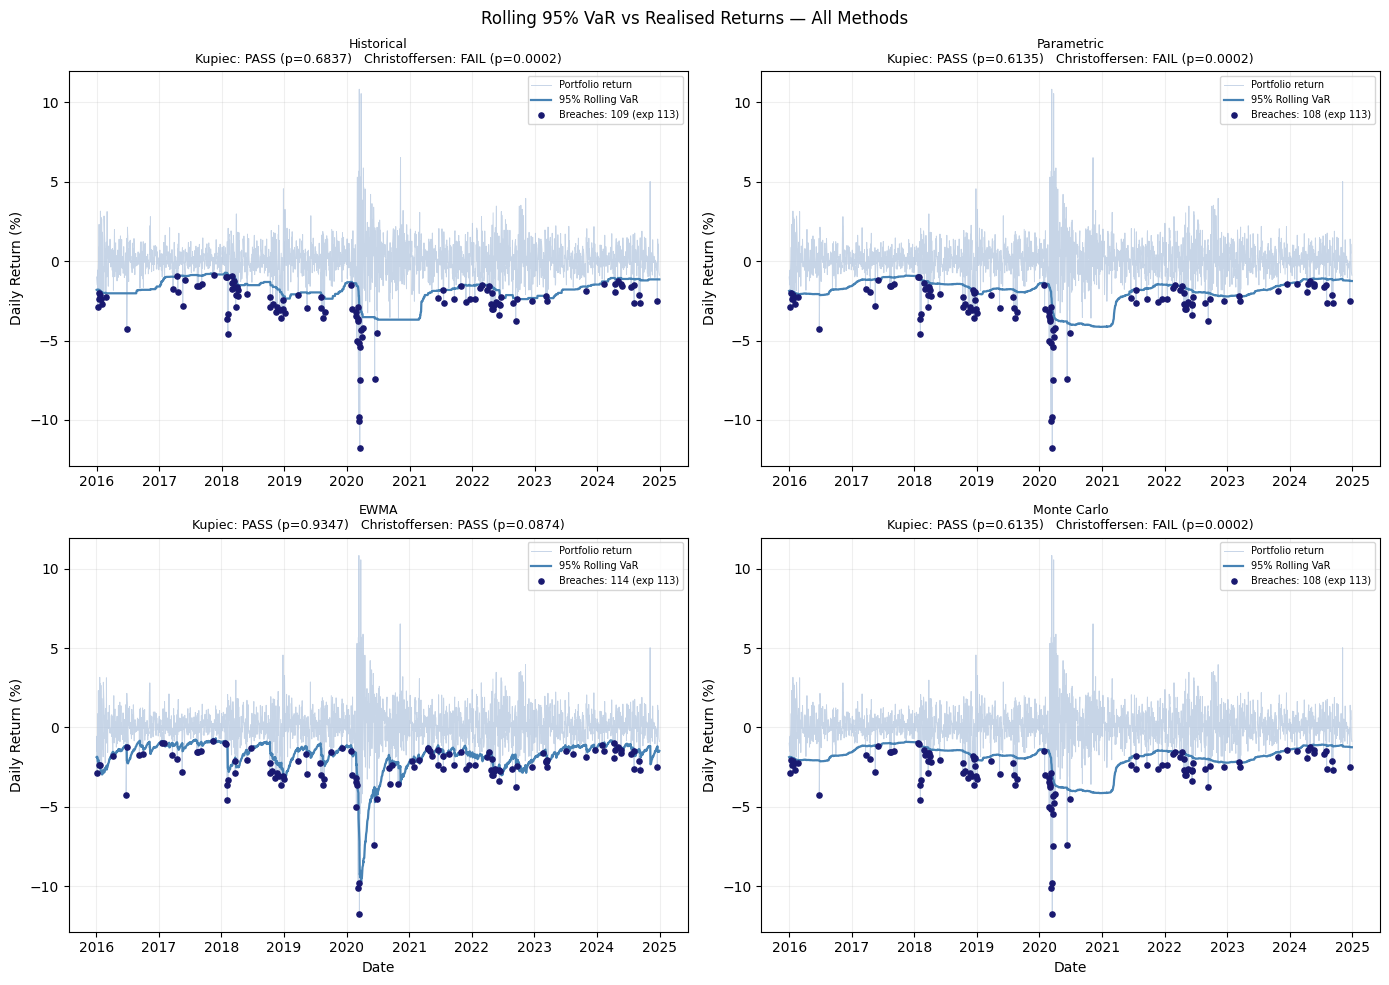

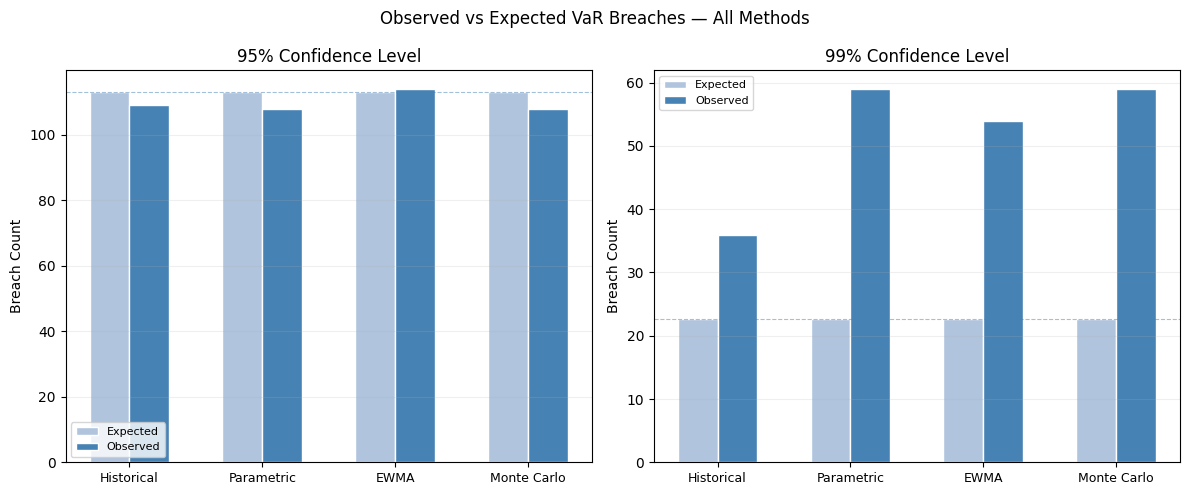

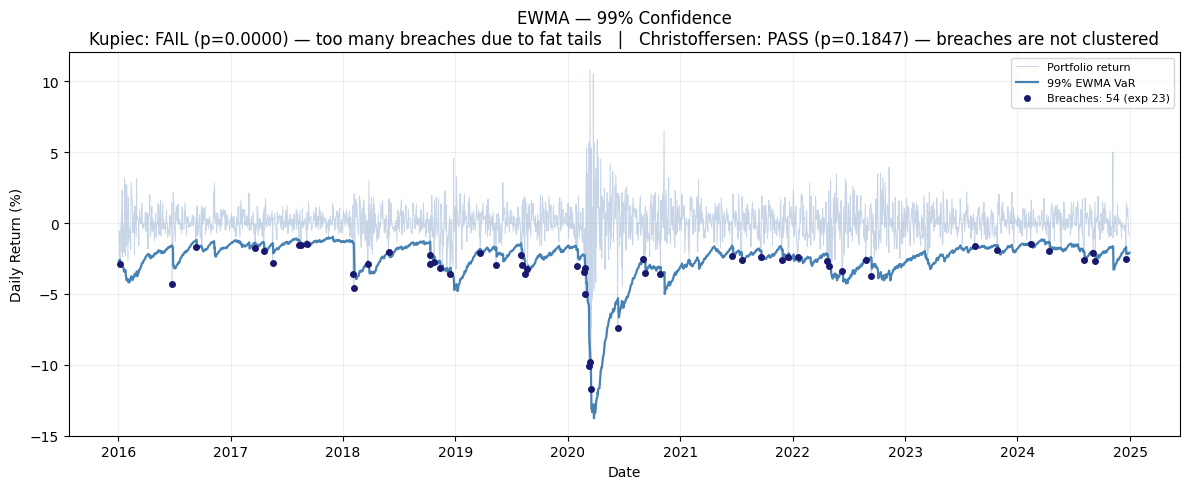

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2, norm

pd.set_option('display.float_format', '{:.4f}'.format)

# Configuration 

weights = np.array([0.20, 0.20, 0.20, 0.20, 0.20])
confidence_levels = [0.95, 0.99]
portfolio_value = 1_000_000
rolling_window  = 250
lam  = 0.94

log_returns = pd.read_csv( '../data/log_returns.csv',index_col=0,parse_dates=True)
assert log_returns.isna().sum().sum() == 0

simple_returns = np.exp(log_returns) - 1
portfolio_simple_returns = simple_returns.dot(weights)
portfolio_returns = np.log1p(portfolio_simple_returns)


# Rolling VaR forecasts
# Each forecast is shifted one period forward.

def rolling_historical_var(returns, window, confidence):
    return returns.rolling(window).apply(
        lambda x: -np.percentile(x, (1 - confidence) * 100),raw=True).shift(1)


def rolling_parametric_var(returns, window, confidence):
    z  = norm.ppf(1 - confidence)
    mu = returns.rolling(window).mean()
    sg = returns.rolling(window).std()
    return (-(mu + z * sg)).shift(1)


def rolling_ewma_var(returns, window, confidence, lam=0.94):
    z = norm.ppf(1 - confidence)
    r = returns.values
    n = len(r)
    ewma_var_arr = np.full(n, np.nan)
    ewma_var_arr[window] = np.var(r[:window])
    for t in range(window + 1, n):
        ewma_var_arr[t] = (lam * ewma_var_arr[t - 1] + (1 - lam) * r[t - 1] ** 2)
    var_series = pd.Series(-z * np.sqrt(ewma_var_arr), index=returns.index)
    return var_series.shift(1)


def rolling_montecarlo_var(returns, window, confidence):
    z  = norm.ppf(1 - confidence)
    mu = returns.rolling(window).mean()
    sg = returns.rolling(window).std()
    return (-(mu + z * sg)).shift(1)


# Statistical tests

def kupiec_test(n_obs, n_breaches, confidence):
    # H0: observed breach rate equals stated tail probability.
    # LR ~ chi2(1) under H0.
    p = 1 - confidence
    p_hat = n_breaches / n_obs
    if p_hat == 0 or p_hat == 1:
        return np.nan, np.nan, False
    lr = -2 * (n_breaches * np.log(p / p_hat) +
        (n_obs - n_breaches) * np.log((1 - p) / (1 - p_hat)))
    p_value = 1 - chi2.cdf(lr, df=1)
    return lr, p_value, p_value > 0.05


def christoffersen_test(breaches):
    # H0: breaches are serially independent.
    # Failure indicates clustering during volatile periods.
    # LR ~ chi2(1) under H0.
    b = breaches.values
    n00 = sum(1 for t in range(1, len(b)) if b[t-1]==0 and b[t]==0)
    n01 = sum(1 for t in range(1, len(b)) if b[t-1]==0 and b[t]==1)
    n10 = sum(1 for t in range(1, len(b)) if b[t-1]==1 and b[t]==0)
    n11 = sum(1 for t in range(1, len(b)) if b[t-1]==1 and b[t]==1)
    pi01 = n01 / (n00 + n01) if (n00 + n01) > 0 else 0
    pi11 = n11 / (n10 + n11) if (n10 + n11) > 0 else 0
    pi   = (n01 + n11) / (n00 + n01 + n10 + n11)
    if pi in (0, 1) or pi01 == 0 or pi11 == 0:
        return np.nan, np.nan, False
    lr = -2 * (
        (n00 + n10) * np.log(1 - pi) +
        (n01 + n11) * np.log(pi) -
        n00 * np.log(1 - pi01) -
        n01 * np.log(pi01) -
        n10 * np.log(1 - pi11) -
        n11 * np.log(pi11))
    p_value = 1 - chi2.cdf(lr, df=1)
    return lr, p_value, p_value > 0.05


# Run backtests
methods = {
    'Historical':  rolling_historical_var,
    'Parametric':  rolling_parametric_var,
    'EWMA':        rolling_ewma_var,
    'Monte Carlo': rolling_montecarlo_var,}

results = {}

for name, fn in methods.items():
    results[name] = {}
    for cl in confidence_levels:
        vs      = fn(portfolio_returns, rolling_window, cl)
        valid   = vs.dropna()
        aligned = portfolio_returns.loc[valid.index]
        breach  = (aligned < -valid).astype(int)
        n       = len(valid)
        nb      = int(breach.sum())
        exp     = n * (1 - cl)

        lr_k, pv_k, pass_k = kupiec_test(n, nb, cl)
        lr_c, pv_c, pass_c = christoffersen_test(breach)

        bv = breach.values
        results[name][cl] = {
            'var_series':    valid,
            'breaches':      breach,
            'n_obs':         n,
            'n_breaches':    nb,
            'expected':      exp,
            'kupiec_lr':     lr_k,
            'kupiec_pval':   pv_k,
            'kupiec_pass':   pass_k,
            'chris_lr':      lr_c,
            'chris_pval':    pv_c,
            'chris_pass':    pass_c,
            'n11': sum(1 for t in range(1,len(bv))
                       if bv[t-1]==1 and bv[t]==1),}


# Consolidated validation table
rows = []
for name in methods:
    for cl in confidence_levels:
        r = results[name][cl]
        verdict = (
            'PASS' if r['kupiec_pass'] and r['chris_pass']
            else 'CONDITIONAL' if r['kupiec_pass']
            else 'FAIL')
        rows.append({
            'Method':        name,
            'CL':            f"{cl*100:.0f}%",
            'Expected':      f"{r['expected']:.1f}",
            'Observed':      r['n_breaches'],
            'Kupiec p':      f"{r['kupiec_pval']:.4f}",
            'Kupiec':        'PASS' if r['kupiec_pass'] else 'FAIL',
            'Chris p':       f"{r['chris_pval']:.4f}",
            'Christoffersen':'PASS' if r['chris_pass'] else 'FAIL',
            'Verdict':       verdict,})

val_table = pd.DataFrame(rows).set_index(['Method', 'CL'])
print("\nModel Validation Summary")
print("=" * 90)
print(val_table.to_string())
print("=" * 90)
print()
print("Verdict: PASS = both tests pass")
print("          CONDITIONAL = Kupiec passes, Christoffersen fails")
print("          FAIL = Kupiec fails")
print()
print("Key findings:")
print(f"  All methods pass Kupiec at 95% — breach counts are")
print(f"  consistent with stated confidence levels under normal")
print(f"  market conditions.")
print()
print(f"  All methods fail Kupiec at 99% — a systematic result.")
print(f"  With ~25 tail observations in 2,514 days, finite-sample")
print(f"  estimation cannot reliably anchor the 99th percentile.")
print(f"  Fat-tailed return distributions compound this.")
print()
print(f"  EWMA is the only method passing Christoffersen at both")
print(f"  confidence levels. Dynamic volatility adjustment prevents")
print(f"  breach clustering during stress periods. All other methods")
print(f"  produce clustered failures — Kupiec cannot detect this.")


# Visualisation

# Figure 1: Rolling VaR vs realised returns, 95% confidence.

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Rolling 95% VaR vs Realised Returns — All Methods",fontsize=12)

method_colors = {
    'Historical':  'steelblue',
    'Parametric':  'steelblue',
    'EWMA':        'steelblue',
    'Monte Carlo': 'steelblue',}

for ax, name in zip(axes.flat, methods):
    r = results[name][0.95]
    dates = r['var_series'].index
    breach_dates = r['breaches'][r['breaches'] == 1].index

    ax.plot(dates,
            portfolio_returns.loc[dates] * 100,
            color='lightsteelblue', linewidth=0.7, alpha=0.7,
            label='Portfolio return')

    ax.plot(dates,
            -r['var_series'] * 100,
            color='steelblue', linewidth=1.6,
            label='95% Rolling VaR')

    ax.scatter(breach_dates,
               portfolio_returns.loc[breach_dates] * 100,
               color='midnightblue', s=14, zorder=5,
               label=f"Breaches: {r['n_breaches']} "
                     f"(exp {r['expected']:.0f})")

    k = 'PASS' if r['kupiec_pass'] else 'FAIL'
    c = 'PASS' if r['chris_pass']  else 'FAIL'

    ax.set_title(
        f"{name}\n"
        f"Kupiec: {k} (p={r['kupiec_pval']:.4f}) "
        f"Christoffersen: {c} (p={r['chris_pval']:.4f})",fontsize=9)
    ax.set_ylabel("Daily Return (%)")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.2)

axes[1, 0].set_xlabel("Date")
axes[1, 1].set_xlabel("Date")

plt.tight_layout()
os.makedirs('../reports', exist_ok=True)
plt.savefig('../reports/06_backtesting.png', dpi=150,
            bbox_inches='tight')
plt.show()


# Figure 2: Observed vs expected breach counts, both confidence levels.


fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Observed vs Expected VaR Breaches — All Methods",fontsize=12)

m_names = list(methods.keys())
x  = np.arange(len(m_names))
w  = 0.30

for ax, cl in zip(axes, confidence_levels):
    exp_vals = [results[m][cl]['expected']   for m in m_names]
    obs_vals = [results[m][cl]['n_breaches'] for m in m_names]

    ax.bar(x - w/2, exp_vals, w,
           label='Expected', color='lightsteelblue',
           edgecolor='white')
    ax.bar(x + w/2, obs_vals, w,
           label='Observed', color='steelblue',
           edgecolor='white')

    ax.axhline(exp_vals[0], color='steelblue',
               linewidth=0.8, linestyle='--', alpha=0.5)

    ax.set_xticks(x)
    ax.set_xticklabels(m_names, fontsize=9)
    ax.set_ylabel("Breach Count")
    ax.set_title(f"{cl*100:.0f}% Confidence Level")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2, axis='y')

plt.tight_layout()
plt.savefig('../reports/06_backtesting_comparison.png', dpi=150,bbox_inches='tight')
plt.show()


# Figure 3: Breach timeline for EWMA at 99%.

fig, ax = plt.subplots(figsize=(12, 5))

r  = results['EWMA'][0.99]
dates = r['var_series'].index
breach_dates = r['breaches'][r['breaches'] == 1].index

ax.plot(dates,
        portfolio_returns.loc[dates] * 100,
        color='lightsteelblue', linewidth=0.7, alpha=0.7,
        label='Portfolio return')

ax.plot(dates,
        -r['var_series'] * 100,
        color='steelblue', linewidth=1.6,
        label='99% EWMA VaR')

ax.scatter(breach_dates,
           portfolio_returns.loc[breach_dates] * 100,
           color='midnightblue', s=16, zorder=5,
           label=f"Breaches: {r['n_breaches']} "
                 f"(exp {r['expected']:.0f})")

ax.set_title(
    "EWMA — 99% Confidence\n"
    f"Kupiec: FAIL (p={r['kupiec_pval']:.4f}) — "
    f"too many breaches due to fat tails   |   "
    f"Christoffersen: PASS (p={r['chris_pval']:.4f}) — "
    f"breaches are not clustered")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Return (%)")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig('../reports/06_backtesting_ewma_99.png', dpi=150,
            bbox_inches='tight')
plt.show()
